## Advanced Models and Model Tuning

This notebook uses the Week 6 Dataset A features, including derived ratios and school-district information, to compare a tuned Random Forest with HistGradientBoosting, XGBoost, and LightGBM. The target is the sale price (`ClosePrice`).

**Evaluation plan:** keep the training window fixed at 18 months, select settings using the six chronological validation months from October 2025 through March 2026, then score the selected models once on the April 2026 test month. Candidate selection uses mean validation MAE; RMSE and R² are reported as supporting metrics.


In [2]:
%pip install xgboost lightgbm

  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
  Using cached lightgbm-4.7.0-py3-none-win_amd64.whl.metadata (18 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)
Using cached lightgbm-4.7.0-py3-none-win_amd64.whl (1.4 MB)

   ---------------------------------------- 0/2 [xgboost]
   ---------------------------------------- 0/2 [xgboost]
   ---------------------------------------- 0/2 [xgboost]
   ---------------------------------------- 0/2 [xgboost]
   ---------------------------------------- 0/2 [xgboost]
   ---------------------------------------- 0/2 [xgboost]
   -------------------- ------------------- 1/2 [lightgbm]
   -------------------- ------------------- 1/2 [lightgbm]
   ---------------------------------------- 2/2 [lightgbm]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# Imports and project configuration
from pathlib import Path
import time

import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import ParameterGrid

# These packages must be installed in the active notebook environment.
try:
    from xgboost import XGBRegressor
    from lightgbm import LGBMRegressor
except ImportError as exc:
    raise ImportError(
        "Install the optional model packages in this kernel with: %pip install xgboost lightgbm"
    ) from exc

import idx_scripts.dataset_a as da
import idx_scripts.features as ft
from idx_scripts.modeling import build_model, fit_and_score
from idx_scripts.splits import validation_months

pd.set_option("display.float_format", "{:,.4f}".format)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

TEST_MONTH = "2026-04"
TRAINING_WINDOW = 18
X = TRAINING_WINDOW
EVAL_MONTHS = validation_months(TEST_MONTH, n_months=6)
RESULTS_DIR = Path("../Rohan/results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
DATA_PATH = Path("../Data_Prep/CRMLSSoldDatasetA.csv")
DISTRICTS_PATH = Path("DistrictAreas2425.shp")  # relative to the notebook's working directory


In [4]:
# Notebook-level compatibility patch: normalize TargetEncoder(cv=KFold(...)) to cv=5.
import sklearn.preprocessing as sklearn_preprocessing
from sklearn.model_selection import KFold
from sklearn.preprocessing import TargetEncoder as _OriginalTargetEncoder

if not getattr(da, "_target_encoder_compat_installed", False):
    class NotebookTargetEncoder(_OriginalTargetEncoder):
        def __init__(self, categories="auto", target_type="auto", smooth="auto",
                     cv=5, shuffle=True, random_state=None):
            if not isinstance(cv, (int, np.integer)):
                splitter = cv
                n_splits = getattr(splitter, "n_splits", None)
                if n_splits is None:
                    raise TypeError(
                        "TargetEncoder cv must be an integer or a splitter with n_splits."
                    )
                cv = int(n_splits)
                shuffle = getattr(splitter, "shuffle", shuffle)
                random_state = getattr(splitter, "random_state", random_state)
            super().__init__(
                categories=categories,
                target_type=target_type,
                smooth=smooth,
                cv=cv,
                shuffle=shuffle,
                random_state=random_state,
            )

    # Cover both `from sklearn.preprocessing import TargetEncoder` and a module-level import in dataset_a.
    sklearn_preprocessing.TargetEncoder = NotebookTargetEncoder
    if hasattr(da, "TargetEncoder"):
        da.TargetEncoder = NotebookTargetEncoder
    da._target_encoder_compat_installed = True

# Small smoke check: verify the old KFold-style constructor is normalized correctly.
_encoder_check = NotebookTargetEncoder(
    target_type="continuous", cv=KFold(n_splits=5, shuffle=True, random_state=0)
)
assert _encoder_check.cv == 5
assert _encoder_check.shuffle is True
assert _encoder_check.random_state == 0
print("TargetEncoder KFold compatibility patch is active.")


TargetEncoder KFold compatibility patch is active.


### Load and prepare the data

The feature script adds ratios and spatial school-district features. The custom preprocessor must be told about those extra numeric and categorical columns; otherwise the notebook would appear to run while leaving the new features out of the model. Infinities from zero denominators are converted to missing values before imputation.


In [ ]:
districts = ft.load_school_districts(DISTRICTS_PATH)
df = da.load_clean(str(DATA_PATH))
df = ft.add_ratios(df)   # need to remove and re-run, shouldn't be included
df = ft.add_school_districts(df, districts)
df = df.replace([np.inf, -np.inf], np.nan)

EXTRA_NUMERIC = ft.RATIO_COLS + ft.DISTRICT_NUMERIC_COLS
EXTRA_CATEGORICAL = ft.DISTRICT_COLS
MODEL_FEATURES = list(dict.fromkeys(
    da.FEATURES + EXTRA_NUMERIC + EXTRA_CATEGORICAL
))
preprocessor = da.DatasetAPreprocessor(
    extra_numeric=EXTRA_NUMERIC,
    extra_categorical=EXTRA_CATEGORICAL,
)

print(f"Dataset shape: {df.shape}")
print(f"Target: {da.TARGET}; model features: {len(MODEL_FEATURES)}")
print(f"Validation months: {[str(m) for m in EVAL_MONTHS]}; test month: {TEST_MONTH}")


Dataset shape: (309019, 26)
Target: ClosePrice; model features: 23
Validation months: ['2025-10', '2025-11', '2025-12', '2026-01', '2026-02', '2026-03']; test month: 2026-04


### Model factories

All estimators use the same custom preprocessing pipeline and raw-dollar target. The untuned Random Forest settings below provide a same-split reference.


In [6]:
def random_forest(**overrides):
    params = {
        "n_estimators": 200,
        "min_samples_leaf": 2,
        "max_features": 1 / 3,
        "n_jobs": -1,
        "random_state": 0,
    }
    params.update(overrides)
    return RandomForestRegressor(**params)

def hist_gradient_boost(**overrides):
    params = {
        "loss": "squared_error", "learning_rate": 0.1, "max_iter": 200,
        "max_leaf_nodes": 31, "min_samples_leaf": 30,
        "l2_regularization": 0.0, "early_stopping": "auto", "random_state": 0,
    }
    params.update(overrides)
    return HistGradientBoostingRegressor(**params)

def xgboost_regressor(**overrides):
    params = {
        "objective": "reg:squarederror", "tree_method": "hist",
        "n_estimators": 500, "max_depth": 6, "learning_rate": 0.05,
        "subsample": 0.8, "colsample_bytree": 0.8, "n_jobs": -1, "random_state": 0,
    }
    params.update(overrides)
    return XGBRegressor(**params)

def lightgbm_regressor(**overrides):
    params = {
        "objective": "regression", "n_estimators": 500, "learning_rate": 0.05,
        "num_leaves": 31, "max_depth": -1, "min_child_samples": 30,
        "subsample": 0.8, "subsample_freq": 1, "colsample_bytree": 0.8,
        "reg_lambda": 0.0, "n_jobs": -1, "random_state": 0, "verbosity": -1,
    }
    params.update(overrides)
    return LGBMRegressor(**params)


### Chronological tuning helper

The helper evaluates every candidate on exactly the same validation months and training window. Each split refits preprocessing and the model on that split's training rows. It accepts fixed settings so Random Forest can be tuned in two stages: first tree complexity, then `max_features`.


In [7]:
def tune_on_chronological_months(model_name, estimator_factory, parameter_grid, fixed_params=None):
    fixed_params = dict(fixed_params or {})
    rows = []
    fitted_candidates = {}
    candidate_params = {}

    for i, grid_params in enumerate(ParameterGrid(parameter_grid), start=1):
        params = {**fixed_params, **grid_params}
        candidate = f"{model_name} {i:02d}"
        candidate_params[candidate] = params
        model = build_model(estimator_factory(**params), preprocessor=preprocessor)
        fitted_candidates[candidate] = model

        for month in EVAL_MONTHS:
            train, validation = da.split(df, month, TRAINING_WINDOW)
            fitted, _, scores = fit_and_score(
                model, train, validation, features=MODEL_FEATURES, target=da.TARGET
            )
            predictions = fitted.predict(validation[MODEL_FEATURES])
            rows.append({
                "model": model_name, "candidate": candidate, "month": str(month),
                "params": repr(params), "n_train": len(train), "n_validation": len(validation),
                "mae": scores["mae"],
                "rmse": mean_squared_error(validation[da.TARGET], predictions) ** 0.5,
                "r2": scores["r2"], "mape": scores["mape"],
            })

    monthly = pd.DataFrame(rows)
    summary = (
        monthly.groupby(["model", "candidate", "params"], as_index=False)
        .agg(validation_mae=("mae", "mean"), validation_rmse=("rmse", "mean"),
             validation_r2=("r2", "mean"), validation_mape=("mape", "mean"),
             validation_r2_sd=("r2", "std"))
        .sort_values(["validation_mae", "validation_r2"], ascending=[True, False])
        .reset_index(drop=True)
    )
    winner = summary.loc[0, "candidate"]
    return fitted_candidates[winner], candidate_params[winner], summary, monthly


## 1. Random Forest tuning

First compare tree depth, split size, and leaf size. Then hold the best complexity settings fixed and compare the fraction of features considered at each split.


In [12]:
rf_complexity_grid = {
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 10],
    "min_samples_leaf": [2, 10],
}
tuned_rf, rf_complexity_params, rf_complexity_summary, rf_complexity_monthly = (
    tune_on_chronological_months(
        "Random Forest complexity", random_forest, rf_complexity_grid
    )
)
rf_complexity_summary


c:\Users\Owner\Documents\IDX\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
c:\Users\Owner\Documents\IDX\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
c:\Users\Owner\Documents\IDX\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify 

,model,candidate,params,validation_mae,validation_rmse,validation_r2,validation_mape,validation_r2_sd
0,Random Forest complexity,Random Forest complexity 01,"{'max_depth': None, 'min_samples_leaf': 2, 'mi...","153,601.8965","312,081.8516",0.8899,0.1214,0.0040
1,Random Forest complexity,Random Forest complexity 09,"{'max_depth': 20, 'min_samples_leaf': 2, 'min_...","154,654.6398","313,255.0759",0.8891,0.1226,0.0041
2,Random Forest complexity,Random Forest complexity 02,"{'max_depth': None, 'min_samples_leaf': 2, 'mi...","154,770.4052","314,970.9633",0.8879,0.1222,0.0041
3,Random Forest complexity,Random Forest complexity 10,"{'max_depth': 20, 'min_samples_leaf': 2, 'min_...","155,867.1623","315,736.8577",0.8874,0.1234,0.0041
4,Random Forest complexity,Random Forest complexity 03,"{'max_depth': None, 'min_samples_leaf': 10, 'm...","160,124.8070","325,337.9226",0.8804,0.1261,0.0042
5,Random Forest complexity,Random Forest complexity 04,"{'max_depth': None, 'min_samples_leaf': 10, 'm...","160,124.8070","325,337.9226",0.8804,0.1261,0.0042
6,Random Forest complexity,Random Forest complexity 11,"{'max_depth': 20, 'min_samples_leaf': 10, 'min...","160,423.6693","325,491.2615",0.8803,0.1264,0.0041
7,Random Forest complexity,Random Forest complexity 12,"{'max_depth': 20, 'min_samples_leaf': 10, 'min...","160,423.6693","325,491.2615",0.8803,0.1264,0.0041
8,Random Forest complexity,Random Forest complexity 07,"{'max_depth': 10, 'min_samples_leaf': 10, 'min...","182,924.2016","349,165.1687",0.8623,0.1501,0.0038
9,Random Forest complexity,Random Forest complexity 08,"{'max_depth': 10, 'min_samples_leaf': 10, 'min...","182,924.2016","349,165.1687",0.8623,0.1501,0.0038


In [13]:
rf_feature_grid = {"max_features": [1 / 3, 0.7]}
tuned_rf, best_rf_params, rf_summary, rf_monthly = tune_on_chronological_months(
    "Random Forest", random_forest, rf_feature_grid, fixed_params=rf_complexity_params
)
rf_summary


c:\Users\Owner\Documents\IDX\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
c:\Users\Owner\Documents\IDX\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
c:\Users\Owner\Documents\IDX\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify 

,model,candidate,params,validation_mae,validation_rmse,validation_r2,validation_mape,validation_r2_sd
0,Random Forest,Random Forest 02,"{'max_depth': None, 'min_samples_leaf': 2, 'mi...","152,795.6989","311,076.6711",0.8906,0.1207,0.0042
1,Random Forest,Random Forest 01,"{'max_depth': None, 'min_samples_leaf': 2, 'mi...","153,601.8965","312,081.8516",0.8899,0.1214,0.0040


In [14]:
rf_monthly.pivot(index="candidate", columns="month", values="mae")


month,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03
candidate,,,,,,
Random Forest 01,"152,872.1471","153,869.9150","149,065.0956","153,505.6391","158,039.4871","154,259.0952"
Random Forest 02,"152,266.7895","152,501.1254","148,594.8614","152,731.5306","156,851.6856","153,828.2010"


## 2. HistGradientBoosting

Compare learning rate and maximum leaf count using the same chronological validation plan.


In [11]:
hgb_grid = {"learning_rate": [0.03, 0.1], "max_leaf_nodes": [15, 31]}
tuned_hgb, best_hgb_params, hgb_summary, hgb_monthly = tune_on_chronological_months(
    "HistGradientBoosting", hist_gradient_boost, hgb_grid
)
hgb_summary


c:\Users\Owner\Documents\IDX\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
c:\Users\Owner\Documents\IDX\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
c:\Users\Owner\Documents\IDX\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify 

,model,candidate,params,validation_mae,validation_rmse,validation_r2,validation_mape,validation_r2_sd
0,HistGradientBoosting,HistGradientBoosting 04,"{'learning_rate': 0.1, 'max_leaf_nodes': 31}","163,711.4695","311,841.1801",0.8902,0.1352,0.0042
1,HistGradientBoosting,HistGradientBoosting 03,"{'learning_rate': 0.1, 'max_leaf_nodes': 15}","171,743.4590","324,644.1142",0.8810,0.1424,0.0043
2,HistGradientBoosting,HistGradientBoosting 02,"{'learning_rate': 0.03, 'max_leaf_nodes': 31}","178,333.4931","337,640.8819",0.8712,0.1490,0.0044
3,HistGradientBoosting,HistGradientBoosting 01,"{'learning_rate': 0.03, 'max_leaf_nodes': 15}","188,182.3695","354,315.3262",0.8582,0.1580,0.0048


## 3. XGBoost

Compare two tree depths and two learning rates. Other settings are held constant for this first search.


In [10]:
xgb_grid = {"max_depth": [4, 8], "learning_rate": [0.03, 0.1]}
tuned_xgb, best_xgb_params, xgb_summary, xgb_monthly = tune_on_chronological_months(
    "XGBoost", xgboost_regressor, xgb_grid
)
xgb_summary


c:\Users\Owner\Documents\IDX\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
c:\Users\Owner\Documents\IDX\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
c:\Users\Owner\Documents\IDX\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify 

,model,candidate,params,validation_mae,validation_rmse,validation_r2,validation_mape,validation_r2_sd
0,XGBoost,XGBoost 04,"{'learning_rate': 0.1, 'max_depth': 8}","147,537.9455","293,532.4204",0.9027,0.1190,0.0049
1,XGBoost,XGBoost 02,"{'learning_rate': 0.03, 'max_depth': 8}","152,423.9073","298,349.5945",0.8995,0.1239,0.0040
2,XGBoost,XGBoost 03,"{'learning_rate': 0.1, 'max_depth': 4}","164,201.8566","315,295.9914",0.8877,0.1348,0.0047
3,XGBoost,XGBoost 01,"{'learning_rate': 0.03, 'max_depth': 4}","178,078.6553","339,142.7841",0.8701,0.1466,0.0046


## 4. LightGBM

Compare tree leaf count and minimum child size.


In [9]:
lgbm_grid = {"num_leaves": [15, 31], "min_child_samples": [20, 50]}
tuned_lgbm, best_lgbm_params, lgbm_summary, lgbm_monthly = tune_on_chronological_months(
    "LightGBM", lightgbm_regressor, lgbm_grid
)
lgbm_summary


c:\Users\Owner\Documents\IDX\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
c:\Users\Owner\Documents\IDX\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
c:\Users\Owner\Documents\IDX\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify 

,model,candidate,params,validation_mae,validation_rmse,validation_r2,validation_mape,validation_r2_sd
0,LightGBM,LightGBM 04,"{'min_child_samples': 50, 'num_leaves': 31}","160,494.8040","306,369.4354",0.8940,0.1328,0.0045
1,LightGBM,LightGBM 02,"{'min_child_samples': 20, 'num_leaves': 31}","161,157.7862","306,544.9347",0.8939,0.1338,0.0044
2,LightGBM,LightGBM 03,"{'min_child_samples': 50, 'num_leaves': 15}","168,915.6728","319,585.5410",0.8846,0.1400,0.0040
3,LightGBM,LightGBM 01,"{'min_child_samples': 20, 'num_leaves': 15}","169,743.7929","320,659.7741",0.8839,0.1409,0.0043


## Compare validation results

Check both average validation performance and month-to-month stability before scoring the final test month.


In [15]:
all_validation = pd.concat(
    [rf_monthly, xgb_monthly, lgbm_monthly, hgb_monthly], ignore_index=True
)
all_summaries = pd.concat(
    [rf_summary, xgb_summary, lgbm_summary, hgb_summary], ignore_index=True
).sort_values("validation_mae").reset_index(drop=True)
all_summaries[["model", "candidate", "params", "validation_mae",
               "validation_rmse", "validation_r2", "validation_r2_sd"]]


,model,candidate,params,validation_mae,validation_rmse,validation_r2,validation_r2_sd
0,XGBoost,XGBoost 04,"{'learning_rate': 0.1, 'max_depth': 8}","147,537.9455","293,532.4204",0.9027,0.0049
1,XGBoost,XGBoost 02,"{'learning_rate': 0.03, 'max_depth': 8}","152,423.9073","298,349.5945",0.8995,0.0040
2,Random Forest,Random Forest 02,"{'max_depth': None, 'min_samples_leaf': 2, 'mi...","152,795.6989","311,076.6711",0.8906,0.0042
3,Random Forest,Random Forest 01,"{'max_depth': None, 'min_samples_leaf': 2, 'mi...","153,601.8965","312,081.8516",0.8899,0.0040
4,LightGBM,LightGBM 04,"{'min_child_samples': 50, 'num_leaves': 31}","160,494.8040","306,369.4354",0.8940,0.0045
5,LightGBM,LightGBM 02,"{'min_child_samples': 20, 'num_leaves': 31}","161,157.7862","306,544.9347",0.8939,0.0044
6,HistGradientBoosting,HistGradientBoosting 04,"{'learning_rate': 0.1, 'max_leaf_nodes': 31}","163,711.4695","311,841.1801",0.8902,0.0042
7,XGBoost,XGBoost 03,"{'learning_rate': 0.1, 'max_depth': 4}","164,201.8566","315,295.9914",0.8877,0.0047
8,LightGBM,LightGBM 03,"{'min_child_samples': 50, 'num_leaves': 15}","168,915.6728","319,585.5410",0.8846,0.0040
9,LightGBM,LightGBM 01,"{'min_child_samples': 20, 'num_leaves': 15}","169,743.7929","320,659.7741",0.8839,0.0043


## Final test-month comparison

The following cell fits each selected model on the 18 months before April 2026 and evaluates it once on April. Do not change model settings based on these test metrics.


In [16]:
test_train, test_data = da.split(df, TEST_MONTH, TRAINING_WINDOW)
winners = {
    "Random Forest (untuned reference)": build_model(
        random_forest(), preprocessor=preprocessor
    ),
    "Random Forest (tuned)": tuned_rf,
    "HistGradientBoosting (tuned)": tuned_hgb,
    "XGBoost (tuned)": tuned_xgb,
    "LightGBM (tuned)": tuned_lgbm,
}
validation_winners = {
    "Random Forest (tuned)": rf_summary.iloc[0],
    "HistGradientBoosting (tuned)": hgb_summary.iloc[0],
    "XGBoost (tuned)": xgb_summary.iloc[0],
    "LightGBM (tuned)": lgbm_summary.iloc[0],
}

final_rows, fitted_winners = [], {}
for name, estimator in winners.items():
    start = time.perf_counter()
    fitted, _, test_scores = fit_and_score(
        estimator, test_train, test_data, features=MODEL_FEATURES, target=da.TARGET
    )
    elapsed = time.perf_counter() - start
    fitted_winners[name] = fitted
    predictions = fitted.predict(test_data[MODEL_FEATURES])
    row = {
        "model": name, "training_window_months": TRAINING_WINDOW,
        "test_mae": test_scores["mae"],
        "test_rmse": mean_squared_error(test_data[da.TARGET], predictions) ** 0.5,
        "test_r2": test_scores["r2"], "test_mape": test_scores["mape"],
        "fit_seconds": round(elapsed, 1),
    }
    if name in validation_winners:
        validation = validation_winners[name]
        row.update({
            "validation_mae": validation["validation_mae"],
            "validation_rmse": validation["validation_rmse"],
            "validation_r2": validation["validation_r2"],
            "selected_params": validation["params"],
        })
    else:
        row["selected_params"] = "baseline settings"
    final_rows.append(row)

comparison = pd.DataFrame(final_rows).sort_values("test_mae").reset_index(drop=True)
comparison


c:\Users\Owner\Documents\IDX\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
c:\Users\Owner\Documents\IDX\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
c:\Users\Owner\Documents\IDX\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify 

,model,training_window_months,test_mae,test_rmse,test_r2,test_mape,fit_seconds,selected_params,validation_mae,validation_rmse,validation_r2
0,XGBoost (tuned),18,"156,290.1260","306,207.2276",0.9031,0.1185,8.5000,"{'learning_rate': 0.1, 'max_depth': 8}","147,537.9455","293,532.4204",0.9027
1,Random Forest (tuned),18,"159,884.9518","325,174.7271",0.8907,0.1193,86.1000,"{'max_depth': None, 'min_samples_leaf': 2, 'mi...","152,795.6989","311,076.6711",0.8906
2,Random Forest (untuned reference),18,"160,748.0944","326,285.4326",0.8900,0.1200,41.2000,baseline settings,NaN,NaN,NaN
3,LightGBM (tuned),18,"168,851.9918","319,772.6583",0.8943,0.1322,5.2000,"{'min_child_samples': 50, 'num_leaves': 31}","160,494.8040","306,369.4354",0.8940
4,HistGradientBoosting (tuned),18,"172,002.1382","324,313.7404",0.8913,0.1345,3.9000,"{'learning_rate': 0.1, 'max_leaf_nodes': 31}","163,711.4695","311,841.1801",0.8902


**Observations**

- XGBoost improves on the tuned Random Forest: test MAE is about $3,550 lower, test RMSE about $18,800 lower, and R² is higher by 0.0123. Its measured fit time was 8.4 seconds versus 99.4 seconds for the tuned forest.
- Random Forest tuning produced only a small gain. On the test month, tuned Random Forest lowered MAE by about $908, or 0.6%, versus the untuned reference. The chosen max_features=0.7 also gave only a modest validation improvement over 1/3.
- The Random Forest complexity results favor deeper trees with small leaves. max_depth=10 performed much worse; max_depth=None and min_samples_leaf=2 were best. Raising leaf size to 10 also hurt performance.
- LightGBM is competitive but trails XGBoost and the forest on validation MAE. Its best validation candidate was num_leaves=31, min_child_samples=50. 
- HistGradientBoosting has slightly higher test R² than tuned RF, but its MAE is about $11,500 worse. Since the tuning selected by MAE, that dollar-error metric is the more relevant ranking here.
- RMSE is roughly twice MAE for the leading models, suggesting a relatively small number of large prediction errors. Looking at errors by sale-price band could show whether those are concentrated among higher-priced homes.

## Save results

Write candidate-level validation metrics, the two-stage forest search, and the final test comparison.


In [17]:
rf_complexity_monthly.to_csv(RESULTS_DIR / "random_forest_complexity_backtest.csv", index=False)
rf_monthly.to_csv(RESULTS_DIR / "random_forest_feature_backtest.csv", index=False)
hgb_monthly.to_csv(RESULTS_DIR / "hist_gradient_boosting_backtest.csv", index=False)
xgb_monthly.to_csv(RESULTS_DIR / "xgboost_backtest.csv", index=False)
lgbm_monthly.to_csv(RESULTS_DIR / "lightgbm_backtest.csv", index=False)
all_summaries.to_csv(RESULTS_DIR / "advanced_model_validation_summary.csv", index=False)
comparison.to_csv(RESULTS_DIR / "advanced_model_test_comparison.csv", index=False)
comparison[["model", "validation_mae", "test_mae", "test_rmse", "test_r2", "fit_seconds"]]


,model,validation_mae,test_mae,test_rmse,test_r2,fit_seconds
0,XGBoost (tuned),"147,537.9455","156,290.1260","306,207.2276",0.9031,8.5000
1,Random Forest (tuned),"152,795.6989","159,884.9518","325,174.7271",0.8907,86.1000
2,Random Forest (untuned reference),NaN,"160,748.0944","326,285.4326",0.8900,41.2000
3,LightGBM (tuned),"160,494.8040","168,851.9918","319,772.6583",0.8943,5.2000
4,HistGradientBoosting (tuned),"163,711.4695","172,002.1382","324,313.7404",0.8913,3.9000


In [18]:
import ast
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Identify the best candidate for each model from its validation-month results.
validation_sources = {
    "Random Forest (tuned)": (rf_monthly, None),
    "HistGradientBoosting (tuned)": (hgb_monthly, None),
    "XGBoost (tuned)": (xgb_monthly, None),
    "LightGBM (tuned)": (lgbm_monthly, None),
    # Candidate 01 is the original RF reference configuration.
    "Random Forest (untuned reference)": (
        rf_complexity_monthly,
        "Random Forest complexity 01",
    ),
}

validation_mae = {}
monthly_best = {}
for model_name, (frame, forced_candidate) in validation_sources.items():
    candidate = forced_candidate or frame.groupby("candidate")["mae"].mean().idxmin()
    chosen = frame.loc[frame["candidate"].eq(candidate)].copy()
    validation_mae[model_name] = chosen["mae"].mean()
    monthly_best[model_name] = chosen.sort_values("month")

test_mae = comparison.set_index("model")["test_mae"].to_dict()
test_rmse = comparison.set_index("model")["test_rmse"].to_dict()
test_r2 = comparison.set_index("model")["test_r2"].to_dict()

model_colors = {
    "XGBoost (tuned)": "#0072B2",
    "Random Forest (tuned)": "#009E73",
    "Random Forest (untuned reference)": "#777777",
    "LightGBM (tuned)": "#CC79A7",
    "HistGradientBoosting (tuned)": "#D55E00",
}


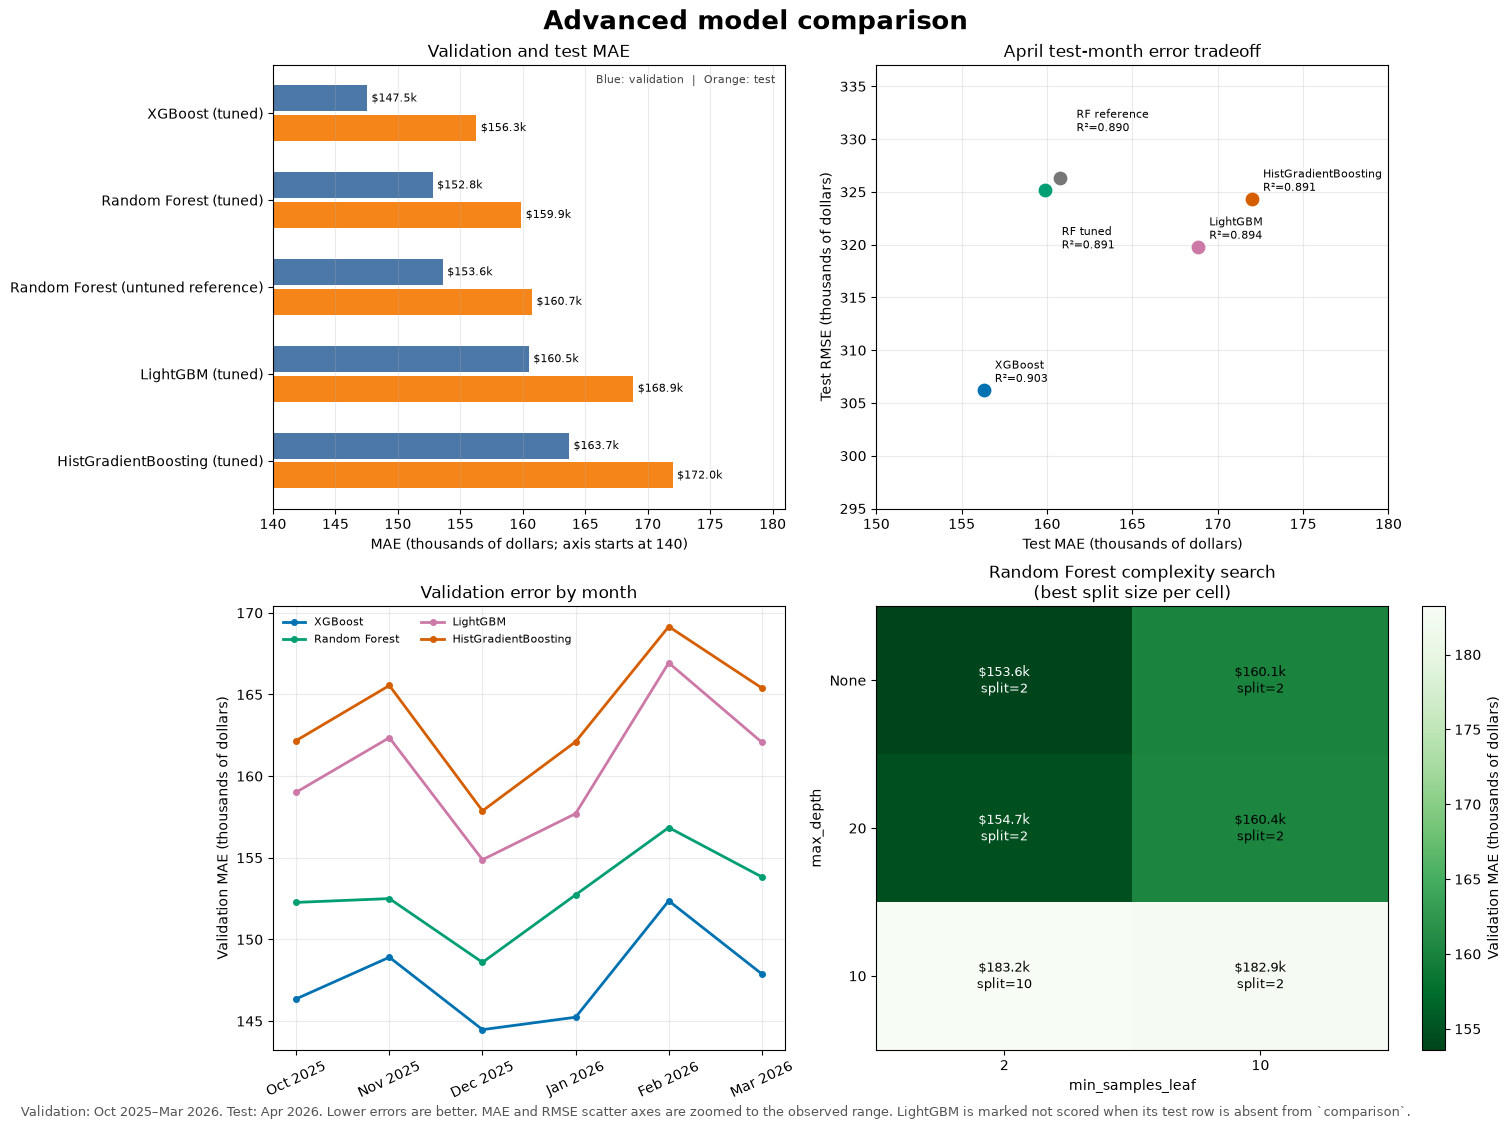

Saved dashboard to: C:\Users\Owner\Documents\IDX\Rohan\results\advanced_model_results_dashboard.png


In [19]:
# Four-panel model-results dashboard
fig, axes = plt.subplots(2, 2, figsize=(15, 11), layout="constrained")
fig.suptitle("Advanced model comparison", fontsize=19, fontweight="bold")

# 1) Mean validation MAE versus April test MAE.
ax = axes[0, 0]
ordered = sorted(validation_mae, key=validation_mae.get)
y = np.arange(len(ordered))
bar_h = 0.34
axis_floor = 140.0  # $000s; a zoomed axis makes small differences readable.
for offset, label, color, source in [
    (-bar_h / 2, "Validation mean", "#4C78A8", validation_mae),
    ( bar_h / 2, "April test", "#F58518", test_mae),
]:
    for row, name in enumerate(ordered):
        value = source.get(name, np.nan)
        ypos = row + offset
        if pd.notna(value):
            value_k = value / 1000
            ax.barh(ypos, value_k - axis_floor, left=axis_floor, height=bar_h * 0.88,
                    color=color, label=label if row == 0 else None)
            ax.text(value_k + 0.35, ypos, f"${value_k:,.1f}k", va="center", fontsize=8)
        else:
            ax.text(179.6, ypos, "not scored", va="center", ha="right", fontsize=8,
                    color="#666666", style="italic")
ax.set_yticks(y, ordered)
ax.invert_yaxis()
ax.set_xlim(axis_floor, 181)
ax.set_xlabel("MAE (thousands of dollars; axis starts at 140)")
ax.set_title("Validation and test MAE")
ax.grid(axis="x", alpha=0.25)
ax.text(0.98, 0.98, "Blue: validation  |  Orange: test", transform=ax.transAxes,
        ha="right", va="top", fontsize=8, color="#444444")

# 2) Test-month dollar-error tradeoff; annotate R² beside each point.
ax = axes[0, 1]
short_names = {
    "XGBoost (tuned)": "XGBoost",
    "Random Forest (tuned)": "RF tuned",
    "Random Forest (untuned reference)": "RF reference",
    "HistGradientBoosting (tuned)": "HistGradientBoosting",
    "LightGBM (tuned)": "LightGBM",
}
for name in comparison["model"]:
    x = test_mae[name] / 1000
    yv = test_rmse[name] / 1000
    ax.scatter(x, yv, s=80, color=model_colors.get(name, "#444444"), zorder=3)
    label = short_names.get(name, name)
    offsets = {"Random Forest (tuned)": (12, -42),
               "Random Forest (untuned reference)": (12, 34)}
    ax.annotate(f"{label}\nR²={test_r2[name]:.3f}",
                (x, yv), xytext=offsets.get(name, (8, 6)),
                textcoords="offset points", fontsize=8)
ax.set_xlim(150, 180)
ax.set_ylim(295, 337)
ax.set_xlabel("Test MAE (thousands of dollars)")
ax.set_ylabel("Test RMSE (thousands of dollars)")
ax.set_title("April test-month error tradeoff")
ax.grid(alpha=0.25)

# 3) Month-by-month validation MAE for the selected candidate of each model.
ax = axes[1, 0]
for name in ["XGBoost (tuned)", "Random Forest (tuned)",
             "LightGBM (tuned)", "HistGradientBoosting (tuned)"]:
    chosen = monthly_best[name]
    months = chosen["month"].tolist()
    labels = [pd.Period(m, freq="M").strftime("%b %Y") for m in months]
    ax.plot(labels, chosen["mae"].to_numpy() / 1000, marker="o", linewidth=2,
            markersize=4, label=name.replace(" (tuned)", ""),
            color=model_colors[name])
ax.set_ylabel("Validation MAE (thousands of dollars)")
ax.set_title("Validation error by month")
ax.grid(alpha=0.25)
ax.legend(frameon=False, ncol=2, fontsize=8)
ax.tick_params(axis="x", rotation=25)

# 4) RF complexity search: best min_samples_split at each depth/leaf-size pair.
ax = axes[1, 1]
rf_rows = []
for candidate, frame in rf_complexity_monthly.groupby("candidate", sort=False):
    params = ast.literal_eval(frame["params"].iloc[0])
    rf_rows.append({
        "candidate": candidate,
        "max_depth": params["max_depth"],
        "depth_label": "None" if params["max_depth"] is None else str(params["max_depth"]),
        "min_samples_leaf": params["min_samples_leaf"],
        "min_samples_split": params["min_samples_split"],
        "mean_mae": frame["mae"].mean(),
    })
rf_grid_summary = pd.DataFrame(rf_rows)
idx = rf_grid_summary.groupby(["depth_label", "min_samples_leaf"])["mean_mae"].idxmin()
rf_best_per_cell = rf_grid_summary.loc[idx].copy()
depth_order = ["None", "20", "10"]
leaf_order = [2, 10]
heat = (rf_best_per_cell.pivot(index="depth_label", columns="min_samples_leaf", values="mean_mae")
        .reindex(index=depth_order, columns=leaf_order) / 1000)
img = ax.imshow(heat.to_numpy(), cmap="Greens_r", aspect="auto")
ax.set_xticks(np.arange(len(leaf_order)), leaf_order)
ax.set_yticks(np.arange(len(depth_order)), depth_order)
ax.set_xlabel("min_samples_leaf")
ax.set_ylabel("max_depth")
ax.set_title("Random Forest complexity search\n(best split size per cell)")
for i, depth in enumerate(depth_order):
    for j, leaf in enumerate(leaf_order):
        value = heat.loc[depth, leaf]
        split = rf_best_per_cell.loc[
            rf_best_per_cell["depth_label"].eq(depth)
            & rf_best_per_cell["min_samples_leaf"].eq(leaf),
            "min_samples_split",
        ].iloc[0]
        text_color = "white" if value < 160 else "black"
        ax.text(j, i, f"${value:.1f}k\nsplit={split}", ha="center", va="center",
                fontsize=9, color=text_color)
fig.colorbar(img, ax=ax, fraction=0.046, pad=0.04, label="Validation MAE (thousands of dollars)")

fig.text(0.01, -0.01,
         "Validation: Oct 2025–Mar 2026. Test: Apr 2026. Lower errors are better. "
         "MAE and RMSE scatter axes are zoomed to the observed range. "
         "LightGBM is marked not scored when its test row is absent from `comparison`.",
         ha="left", fontsize=9, color="#555555")
dashboard_path = RESULTS_DIR / "advanced_model_results_dashboard.png"
fig.savefig(dashboard_path, dpi=180, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved dashboard to: {dashboard_path.resolve()}")
